# Practical 7 - Image Sharpening and Edges

Aim: Sharpen an image using Laplacian, Sobel, Canny and unsharp masking.

Name: Navjot Singh
Roll No: 2025010071


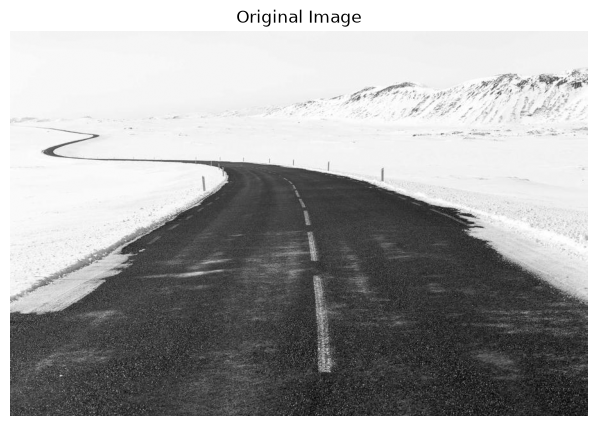

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Name: Navjot Singh")
print("Roll No: 2025010071")

img = cv2.imread("images/navjot_d.jpg", cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(8, 5))
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.show()

In [2]:
# laplacian sharpening
laplacian = cv2.Laplacian(img, cv2.CV_64F)
sharpened = np.uint8(np.clip(img.astype(np.float32) - laplacian, 0, 255))

In [3]:
# sobel gradient
sobel_x = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
sobel = cv2.magnitude(sobel_x, sobel_y)
sobel = np.uint8(np.clip(sobel, 0, 255))

In [4]:
# canny edges and unsharp masking
canny = cv2.Canny(img, 100, 200)

blur = cv2.GaussianBlur(img, (5, 5), 3)
unsharp = cv2.addWeighted(img, 1.5, blur, -0.5, 0)

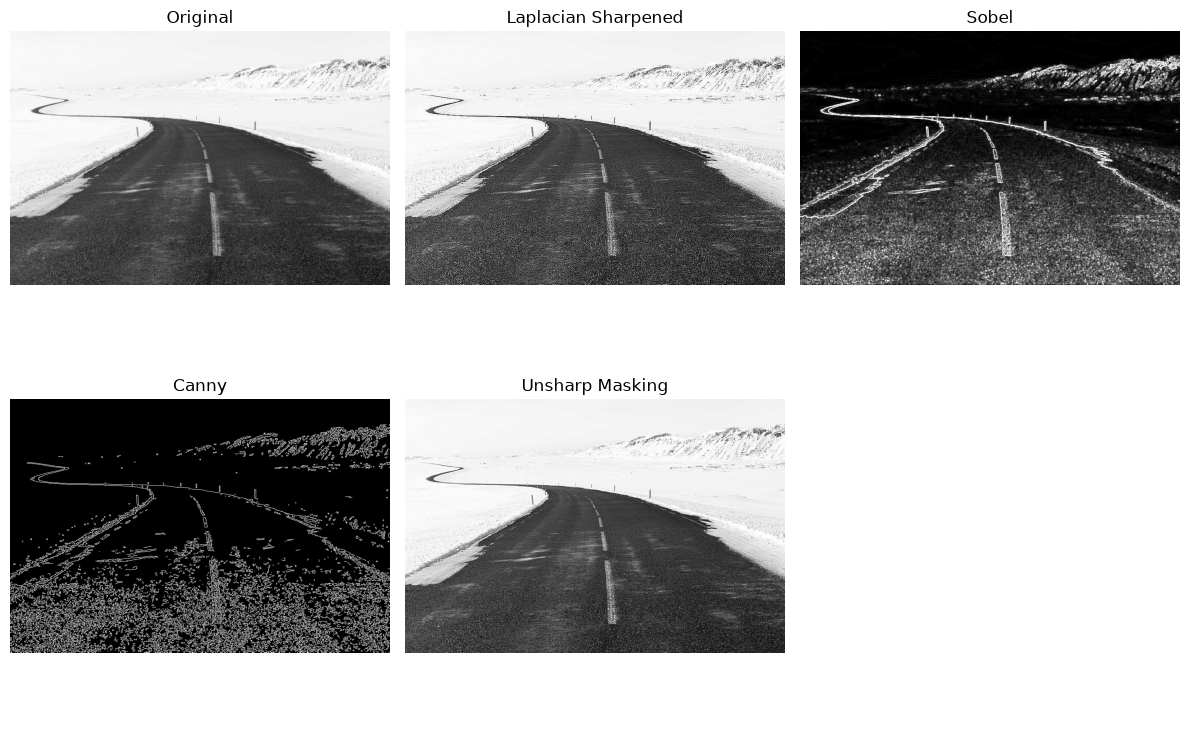

In [5]:
titles = ["Original", "Laplacian Sharpened", "Sobel", "Canny", "Unsharp Masking"]
images = [img, sharpened, sobel, canny, unsharp]

plt.figure(figsize=(12, 8))
for i in range(5):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.subplot(2, 3, 6)
plt.axis("off")

plt.tight_layout()
plt.show()